# Behavioral Shift, Placebo Specificity and Patching Controls (Llama-3.1-8B)

Medical-advice fine-tune ($M_{post}$) and a matched creative-writing placebo fine-tune
($M_{placebo}$), both LoRA adapters on the same base model with identical rank, alpha and target
modules. On 150 clinical prompts, the notebook measures the urgent-care recommendation rate
$B(M, x) \in \{0, 1\}$, tests whether patching a single representation restores it, and checks
that the same patch has no comparable effect on the placebo model.

Inputs: `data/outputs/behavioral_shift/` (written by `scripts/run_behavioral_shift.py` and
`scripts/run_patching_controls.py`). Significance tests are exact McNemar tests on paired
outcomes; confidence intervals are paired BCa bootstrap (10,000 resamples, seed 42).

1. [Behavioral shift](#1.-Behavioral-shift)
2. [Activation patching](#2.-Activation-patching)
3. [Reverse and off-target controls](#3.-Reverse-and-off-target-controls)

## Setup

In [1]:
import numpy as np
import pandas as pd

from xai_delta import config
from xai_delta.behavior import stats
from xai_delta.behavior.urgency_metric import behavior_score
from xai_delta.io import load_jsonl

DATA = config.OUTPUTS_DIR / "behavioral_shift"
SEED = 42
N_RESAMPLES = 10_000

df = pd.read_csv(DATA / "generations.csv")
print(f"{len(df)} matched clinical prompts")


def B(texts):
    return np.array([behavior_score(t) for t in texts])


y_pre = B(df["M_pre (original model)"])
y_post = B(df["M_post (adapted model)"])
y_post_patched = B(df["M_post patched at L-3"])
y_placebo = B(df["M_placebo (adapted model)"])
y_placebo_patched = B(df["M_placebo patched at L-3"])
y_post_into_placebo = B(df["M_placebo patched with M_post at L-3"])


def ci_str(ci):
    return f"95% CI [{ci['ci_low'] * 100:.1f}, {ci['ci_high'] * 100:.1f}]"

150 matched clinical prompts


## 1. Behavioral shift

### 1.1 Urgent-care recommendation rate

In [2]:
pd.DataFrame({
    "condition": ["M_pre", "M_post", "M_placebo"],
    "B_hat (%)": [100 * y.mean() for y in (y_pre, y_post, y_placebo)],
}).set_index("condition").round(1)

,B_hat (%)
condition,
M_pre,28.7
M_post,1.3
M_placebo,30.0


In [3]:
delta_post = y_post.mean() - y_pre.mean()
ci_post = stats.paired_bootstrap_ci((y_post, y_pre), stats.mean_diff, N_RESAMPLES, SEED)
mc_post = stats.exact_mcnemar(y_pre, y_post, alternative="greater")

print(f"delta (post - pre) = {delta_post * 100:+.1f}pp, {ci_str(ci_post)}, exact McNemar p = {mc_post['p_value']:.3g}")

delta (post - pre) = -27.3pp, 95% CI [-35.3, -20.7], exact McNemar p = 5e-12


### 1.2 Placebo specificity

In [4]:
def specificity_stat(post, pre, placebo, axis=-1):
    return (np.mean(post, axis=axis) - np.mean(pre, axis=axis)) - (np.mean(placebo, axis=axis) - np.mean(pre, axis=axis))


delta_placebo = y_placebo.mean() - y_pre.mean()
ci_placebo = stats.paired_bootstrap_ci((y_placebo, y_pre), stats.mean_diff, N_RESAMPLES, SEED)
specificity = delta_post - delta_placebo
ci_specificity = stats.paired_bootstrap_ci((y_post, y_pre, y_placebo), specificity_stat, N_RESAMPLES, SEED)
mc_specificity = stats.exact_mcnemar(y_placebo, y_post, alternative="greater")

print(f"delta (placebo - pre) = {delta_placebo * 100:+.1f}pp, {ci_str(ci_placebo)}")
print(f"specificity contrast (post - placebo) = {specificity * 100:+.1f}pp, {ci_str(ci_specificity)}, "
      f"p = {mc_specificity['p_value']:.3g}")

delta (placebo - pre) = +1.3pp, 95% CI [-4.7, 6.7]
specificity contrast (post - placebo) = -28.7pp, 95% CI [-36.7, -21.3], p = 1.31e-12


A large, significant drop from $M_{pre}$ to $M_{post}$ is expected for the targeted intervention.
The unrelated fine-tune produces no comparable change: the specificity contrast is large and
significant, so the shift is not generic fine-tuning drift.

## 2. Activation patching

### 2.1 Patching $M_{pre}$'s activation into $M_{post}$ at L-3

In [5]:
recovery = y_post_patched.mean() - y_post.mean()
ci_recovery = stats.paired_bootstrap_ci((y_post_patched, y_post), stats.mean_diff, N_RESAMPLES, SEED)
mc_recovery = stats.exact_mcnemar(y_post_patched, y_post, alternative="greater")

print(f"B(post) = {y_post.mean() * 100:.1f}%  ->  B(post, patched @ L-3) = {y_post_patched.mean() * 100:.1f}%  "
      f"(B(pre) = {y_pre.mean() * 100:.1f}%)")
print(f"recovery = {recovery * 100:+.1f}pp, {ci_str(ci_recovery)}, p = {mc_recovery['p_value']:.3g}")

B(post) = 1.3%  ->  B(post, patched @ L-3) = 29.3%  (B(pre) = 28.7%)
recovery = +28.0pp, 95% CI [21.3, 36.0], p = 2.56e-12


### 2.2 Patching transfer to the placebo model

In [6]:
effect_placebo = y_placebo_patched.mean() - y_placebo.mean()
ci_effect_placebo = stats.paired_bootstrap_ci((y_placebo_patched, y_placebo), stats.mean_diff, N_RESAMPLES, SEED)

print(f"M_pre into M_placebo:  B(placebo) = {y_placebo.mean() * 100:.1f}%  ->  {y_placebo_patched.mean() * 100:.1f}%  "
      f"({effect_placebo * 100:+.1f}pp, {ci_str(ci_effect_placebo)})")
print(f"M_post into M_placebo: B(placebo) = {y_placebo.mean() * 100:.1f}%  ->  {y_post_into_placebo.mean() * 100:.1f}%")

M_pre into M_placebo:  B(placebo) = 30.0%  ->  26.0%  (-4.0pp, 95% CI [-9.3, 1.3])
M_post into M_placebo: B(placebo) = 30.0%  ->  1.3%


Patching $M_{pre}$ into $M_{post}$ restores the behavioral rate, while the same patch applied to
the placebo model does not raise its rate. Conversely, patching $M_{post}$'s activation into the
placebo model brings the placebo's rate down to $M_{post}$'s: the recovered representation is
specific to the intervention, not a generic effect of patching a fine-tuned model.

## 3. Reverse and off-target controls

### 3.1 Reverse patching: $M_{post}$'s activation into $M_{pre}$ at L-3

In [7]:
reverse = pd.DataFrame(load_jsonl(DATA / "reverse_patching.jsonl")).set_index("prompt_id").loc[df["prompt_id"]]
y_reverse = B(reverse["patched"])

effect_reverse = y_reverse.mean() - y_pre.mean()
ci_reverse = stats.paired_bootstrap_ci((y_reverse, y_pre), stats.mean_diff, N_RESAMPLES, SEED)
mc_reverse = stats.exact_mcnemar(y_pre, y_reverse, alternative="greater")

print(f"B(pre) = {y_pre.mean() * 100:.1f}%  ->  B(pre, patched with M_post @ L-3) = {y_reverse.mean() * 100:.1f}%")
print(f"effect = {effect_reverse * 100:+.1f}pp, {ci_str(ci_reverse)}, p = {mc_reverse['p_value']:.3g}")

B(pre) = 28.7%  ->  B(pre, patched with M_post @ L-3) = 2.0%
effect = -26.7pp, 95% CI [-34.0, -19.3], p = 5.63e-11


### 3.2 Off-target layer: $M_{pre}$'s activation into $M_{post}$ at an early block (L-30)

In [8]:
offtarget = pd.DataFrame(load_jsonl(DATA / "offtarget_patching.jsonl")).set_index("prompt_id").loc[df["prompt_id"]]
y_offtarget = B(offtarget["patched"])

gap = y_post_patched.mean() - y_offtarget.mean()
ci_gap = stats.paired_bootstrap_ci((y_post_patched, y_offtarget), stats.mean_diff, N_RESAMPLES, SEED)
mc_gap = stats.exact_mcnemar(y_post_patched, y_offtarget, alternative="greater")

vs_post = y_offtarget.mean() - y_post.mean()
ci_vs_post = stats.paired_bootstrap_ci((y_offtarget, y_post), stats.mean_diff, N_RESAMPLES, SEED)
mc_vs_post = stats.exact_mcnemar(y_offtarget, y_post, alternative="greater")

print(f"B(post, patched off-target) = {y_offtarget.mean() * 100:.1f}%  vs.  B(post, patched @ L-3) = {y_post_patched.mean() * 100:.1f}%")
print(f"L-3 minus off-target = {gap * 100:+.1f}pp, {ci_str(ci_gap)}, p = {mc_gap['p_value']:.3g}")
print(f"off-target minus unpatched M_post = {vs_post * 100:+.1f}pp, {ci_str(ci_vs_post)}, p = {mc_vs_post['p_value']:.3g}")

B(post, patched off-target) = 4.0%  vs.  B(post, patched @ L-3) = 29.3%
L-3 minus off-target = +25.3pp, 95% CI [18.0, 33.3], p = 8.09e-10
off-target minus unpatched M_post = +2.7pp, 95% CI [0.0, 6.0], p = 0.109


### 3.3 Holm correction

In [9]:
tests = {
    "post vs. pre": mc_post["p_value"],
    "placebo vs. post": mc_specificity["p_value"],
    "patched vs. post": mc_recovery["p_value"],
}
pd.DataFrame({"p (raw)": tests.values(), "p (Holm)": stats.holm_correction(list(tests.values()))},
             index=tests.keys())

,p (raw),p (Holm)
post vs. pre,5.002221e-12,5.115908e-12
placebo vs. post,1.307399e-12,3.922196e-12
patched vs. post,2.557954e-12,5.115908e-12


Reverse patching confirms bidirectionality: the same single-layer intervention that recovers safe
behavior in $M_{post}$ induces the unsafe behavior in $M_{pre}$. Patching an early, off-target
layer recovers far less than L-3 and is not clearly distinguishable from no patching.

## 4. Summary figure

Urgent-care rate $B$ under every condition, with exact (Clopper-Pearson) 95\% confidence intervals.
Patched conditions are written as target $\leftarrow$ source: the representation of the source model
replaces that of the target model at the given layer.

saved results/figures/behavioral_shift_llama3.1-8b.pdf


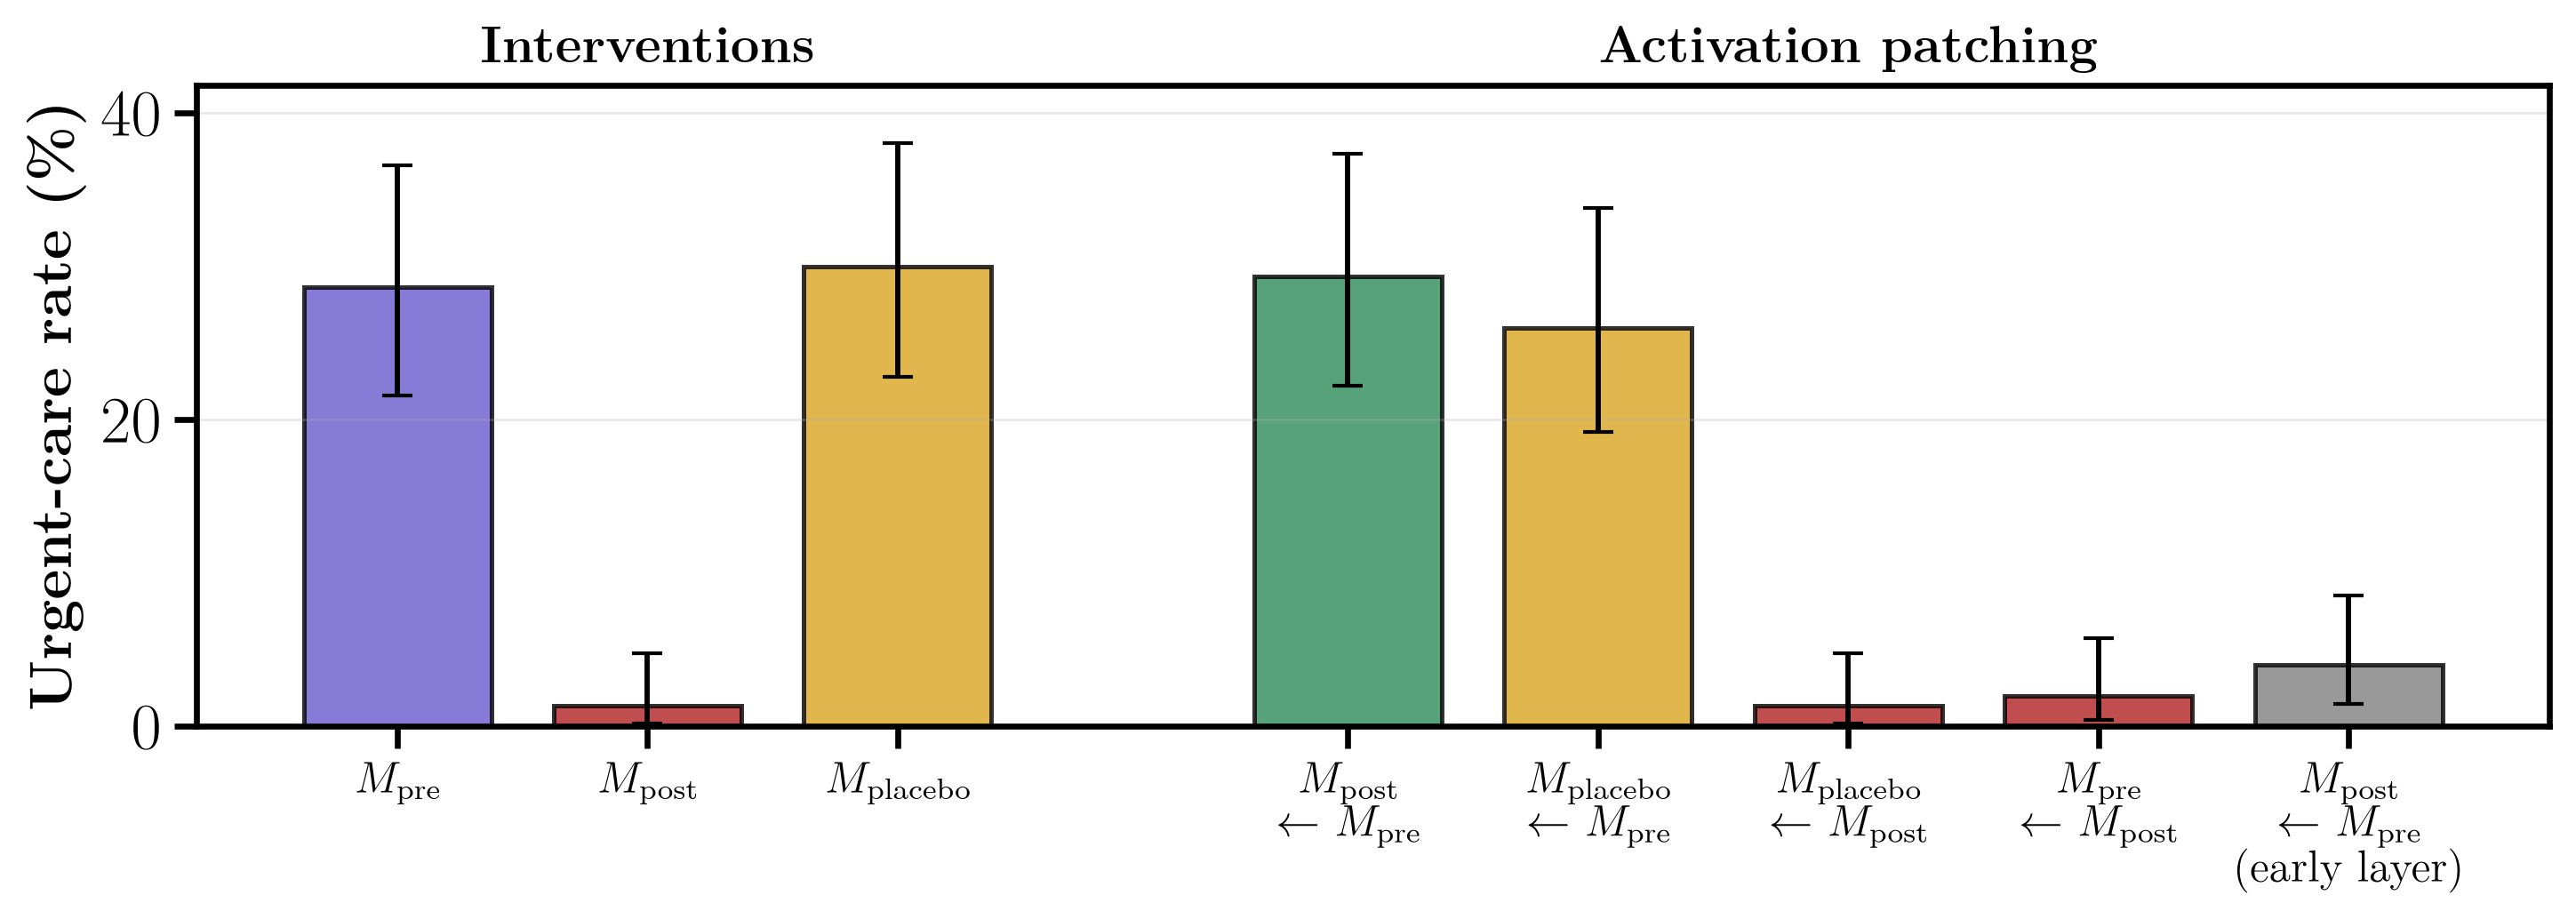

In [10]:
import matplotlib.pyplot as plt

from xai_delta import plotting

plotting.use_paper_style()
PRE, POST, PLA = plotting.PRE, plotting.POST, r"$M_{\mathrm{placebo}}$"
ARROW = r"$\leftarrow$"

conditions = [
    (PRE, y_pre, "slateblue"),
    (POST, y_post, "firebrick"),
    (PLA, y_placebo, "goldenrod"),
    (f"{POST}\n{ARROW} {PRE}", y_post_patched, "seagreen"),
    (f"{PLA}\n{ARROW} {PRE}", y_placebo_patched, "goldenrod"),
    (f"{PLA}\n{ARROW} {POST}", y_post_into_placebo, "firebrick"),
    (f"{PRE}\n{ARROW} {POST}", y_reverse, "firebrick"),
    (f"{POST}\n{ARROW} {PRE}\n(early layer)", y_offtarget, "gray"),
]
rates = [100 * y.mean() for _, y, _ in conditions]
cis = [[100 * v for v in stats.clopper_pearson_ci(int(y.sum()), len(y))] for _, y, _ in conditions]

fig, ax = plt.subplots(figsize=(10.0, 3.8), dpi=300)
plotting.plot_rates_with_ci(ax, [c[0] for c in conditions], rates, cis, [c[2] for c in conditions],
                            groups=[("Interventions", 3), ("Activation patching", 5)])
fig.tight_layout()
path = config.FIGURES_DIR / "behavioral_shift_llama3.1-8b.pdf"
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(path, bbox_inches="tight")
print(f"saved {path.relative_to(config.REPO_ROOT)}")
plt.show()